# Modèle de Cramér-Lundberg avec un processus de comptage « à impact »

**Note d'analyse pour le N+1**

On étudie ce que deviennent les propriétés du modèle de Cramér-Lundberg

$$R_t = u + ct - \sum_{i=1}^{N_t} Y_i$$

quand le processus de Poisson $N$ est remplacé par un modèle à impact : chaque sinistre « spontané » peut en déclencher d'autres peu de temps après (catastrophes naturelles, cyber, soins dentaires en série...).

Plan :
1. Rappels sur le modèle de Poisson (référence)
2. Le modèle à impact : construction et simulation
3. Espérance et variance du nombre de sinistres à toute date
4. Rôle des paramètres
5. Montants des sinistres : lois discrètes et continues
6. Probabilité de ruine
7. Propriétés du cours : ce qui reste vrai, ce qui ne l'est plus
8. Synthèse

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2024)

# paramètres du modèle
T = 10.0      # horizon en années
mu = 1.0      # fréquence des sinistres spontanés (par an)
alpha = 0.8   # force de l'impact juste après un sinistre
beta = 1.2    # vitesse à laquelle l'impact s'éteint
facteur = 2   # poids du 2e chaos : 2 dans le sujet, 1 dans l'article

## 1. Rappels : le modèle de Poisson

Avec $N$ Poisson d'intensité $\mu$ et des $Y_i$ i.i.d. indépendants de $N$, de moyenne $m$ :

- $\mathbb E[N_t]=\operatorname{Var}(N_t)=\mu t$, accroissements indépendants et stationnaires, sauts de taille 1 ;
- Wald : $\mathbb E[S_t]=\mu t\, m$ et $\operatorname{Var}(S_t)=\mu t\,\mathbb E[Y^2]$ ;
- condition de profit net : $c>\mu m$, on écrit $c=(1+\eta)\mu m$ ;
- Lundberg : $\psi(u)\le e^{-Ru}$ avec $\mu(M_Y(R)-1)=cR$ ;
- sinistres exponentiels : $\psi(u)=\frac{1}{1+\eta}\exp\!\big(-\frac{\eta u}{(1+\eta)m}\big)$ et $R=\frac1m-\frac{\mu}{c}$.

## 2. Le modèle à impact

On tire une mesure de Poisson d'intensité 1 sur $[0,T]\times[0,M]$ (algorithme 1 du sujet), puis :

- **sinistres spontanés** : les points sous la hauteur $\mu$, $N^{(1)}_t=\sum_i \mathbf 1_{\theta_i\le\mu}\mathbf 1_{t_i\le t}$. Le nombre de points dans $[0,t]\times[0,\mu]$ est Poisson d'aire $\mu t$, donc $N^{(1)}$ est un Poisson($\mu$) ;
- **sinistres induits** : chaque sinistre spontané en $t_{i_1}$ ouvre une zone d'impact $\{\mu<\theta\le\mu+\Phi(t-t_{i_1})\}$ avec le noyau exponentiel $\Phi(u)=\alpha e^{-\beta u}$. Un point qui tombe dedans est un sinistre induit :

$$N^{(2)}_t = 2\sum_{i_1}\sum_{i_2:\,t_{i_2}>t_{i_1}}\mathbf 1_{\theta_{i_1}\le\mu}\,\mathbf 1_{\mu<\theta_{i_2}\le\mu+\Phi(t_{i_2}-t_{i_1})}\,\mathbf 1_{t_{i_2}\le t}.$$

Contraintes : $\mu>0$, $0<\alpha<\beta$ et $M\ge\mu+\alpha$ pour que la zone d'impact tienne dans le rectangle (on prend $M=\mu+\alpha$). C'est l'idée du thinning (Chen) : on garde un point quand sa hauteur est sous l'intensité.

Les zones d'impact sont au-dessus de $\mu$ : les points « parents » et les points « enfants candidats » sont donc dans des régions disjointes, et donc indépendants. Attention, $N^{(2)}$ dépend quand même de $N^{(1)}$, puisque les zones sont placées là où sont les parents.

**Comparaison avec l'article.** Dans Hillairet & Réveillac (2024, Déf. 5.1 et Prop. 5.2), la 2e génération s'écrit $\frac1{2!}I^2(b_2)$ avec $b_2$ qui utilise $\theta_2\le\Phi(t_2-t_1)$, **sans** décalage de $\mu$ : la zone des enfants chevauche $[0,\mu]$ et un même point peut être à la fois spontané et induit, c'est le mécanisme de la Remarque 5.4. Le $\frac1{2!}$ compense la symétrisation sur les paires ordonnées, ce qui correspond à `facteur = 1`. Le sujet décale la bande au-dessus de $\mu$ et met un facteur 2 : on garde ce choix dans `facteur`.

In [2]:
def Phi(u, alpha, beta):
    # noyau exponentiel, nul avant le sinistre
    return np.where(u > 0, alpha * np.exp(-beta * np.abs(u)), 0.0)

def simule_P(T, M):
    # algorithme 1 : n ~ Poisson(MT), temps uniformes triés, hauteurs uniformes
    n = rng.poisson(M * T)
    t = np.sort(rng.uniform(0, T, n))
    theta = rng.uniform(0, M, n)
    return t, theta

def sauts_N(t, theta, mu, alpha, beta, facteur=facteur):
    # les parents sont les points sous la ligne mu
    parent = theta <= mu
    # dt[i, j] = temps écoulé entre le point i et le point j
    dt = t[None, :] - t[:, None]
    # le point j est dans la zone d'impact du point i
    dans_zone = (dt > 0) & (theta[None, :] > mu) & (theta[None, :] <= mu + Phi(dt, alpha, beta))
    # pour chaque point, combien de parents l'ont induit
    nb_parents = (dans_zone & parent[:, None]).sum(axis=0)
    return parent.astype(int), facteur * nb_parents

def simule_impact(T, mu, alpha, beta, facteur=facteur):
    # instants où N saute, et taille de chaque saut
    t, theta = simule_P(T, mu + alpha)
    s1, s2 = sauts_N(t, theta, mu, alpha, beta, facteur)
    s = s1 + s2
    return t[s > 0], s[s > 0]

def simule_poisson(T, lam):
    n = rng.poisson(lam * T)
    return np.sort(rng.uniform(0, T, n)), np.ones(n, dtype=int)

def N_sur_grille(temps, sauts, grille):
    # valeur de N_t pour chaque t de la grille
    return np.array([sauts[temps <= x].sum() for x in grille])

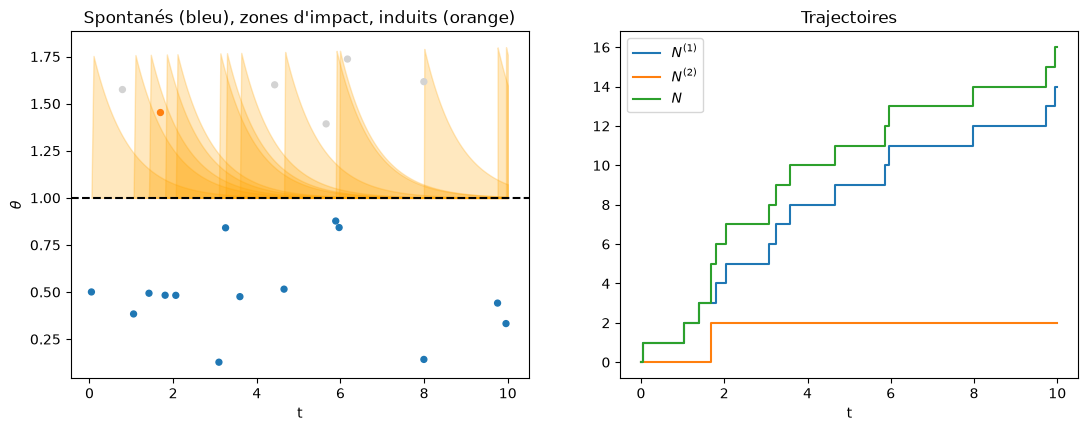

In [3]:
t, theta = simule_P(T, mu + alpha)
s1, s2 = sauts_N(t, theta, mu, alpha, beta)
grille = np.linspace(0, T, 500)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
# une zone d'impact orange par sinistre spontané
for i in np.where(theta <= mu)[0]:
    x = np.linspace(t[i], T, 200)
    ax[0].fill_between(x, mu, mu + Phi(x - t[i], alpha, beta), color="orange", alpha=0.25)
couleur = np.where(theta <= mu, "tab:blue", np.where(s2 > 0, "tab:orange", "lightgrey"))
ax[0].scatter(t, theta, c=couleur, s=18)
ax[0].axhline(mu, ls="--", c="k")
ax[0].set(xlabel="t", ylabel=r"$\theta$", title="Spontanés (bleu), zones d'impact, induits (orange)")
ax[1].step(grille, N_sur_grille(t, s1, grille), label=r"$N^{(1)}$")
ax[1].step(grille, N_sur_grille(t, s2, grille), label=r"$N^{(2)}$")
ax[1].step(grille, N_sur_grille(t, s1 + s2, grille), label=r"$N$")
ax[1].legend(); ax[1].set(xlabel="t", title="Trajectoires")
plt.show()

Un point peut tomber dans les zones d'impact de plusieurs sinistres spontanés : il est compté une fois par parent et $N$ fait un saut de taille $>1$. Avec `facteur = 2`, chaque sinistre induit compte déjà pour 2. $N$ est entier, croissant et constant par morceaux, mais ce n'est pas un processus de comptage au sens strict. Dans la suite, un saut de taille $k$ correspond à $k$ sinistres survenus au même instant.

## 3. Espérance et variance du nombre de sinistres à toute date

**Espérance.** $\mathbb E[N^{(1)}_t]=\mu t$. Pour $N^{(2)}$, la formule de Mecke remplace la somme sur les paires de points par une intégrale double. Le sujet écrit l'intégrale en $t_2$ sur $[0,t_1]$ ; c'est une coquille, le noyau est nul pour $t_2<t_1$, il faut intégrer $t_1$ sur $[0,t_2]$ :

$$\mathbb E[N^{(2)}_t]=2\int_0^t\!\!\int_0^{t_2}\!\!\int_0^M\!\!\int_0^M \mathbf 1_{\theta_1\le\mu}\mathbf 1_{\mu<\theta_2\le\mu+\Phi(t_2-t_1)}\,d\theta_2\,d\theta_1\,dt_1\,dt_2
=2\mu\int_0^t\!\!\int_0^{t_2}\alpha e^{-\beta(t_2-t_1)}dt_1\,dt_2
=2\,\frac{\mu\alpha}{\beta}\Big(t-\frac{1-e^{-\beta t}}{\beta}\Big).$$

Donc
$$\boxed{\mathbb E[N_t]=\mu t+2\,\frac{\mu\alpha}{\beta}\Big(t-\frac{1-e^{-\beta t}}{\beta}\Big)}\qquad\text{et}\qquad \frac{\mathbb E[N_t]}{t}\xrightarrow[t\to\infty]{}\mu\Big(1+\frac{2\alpha}{\beta}\Big).$$

**Variance.** Sachant les parents $t_1,\dots,t_p$, les enfants sont les points d'une mesure de Poisson tombés dans les zones. Si $A(s)=\frac\alpha\beta(1-e^{-\beta(T-s)})$ est l'aire de la zone d'un parent né en $s$ et $B(s,s')=\frac\alpha\beta\big(e^{-\beta(s'-s)}-e^{-\beta(T-s)}\big)$ l'aire commune aux zones de deux parents $s<s'$, la formule de la variance totale et la formule de Campbell donnent
$$\operatorname{Var}(N_T)=\mu\int_0^T\big(1+2A(s)\big)^2ds+4\Big(\mu\int_0^TA(s)\,ds+2\mu^2\iint_{s<s'}B(s,s')\,ds\,ds'\Big),$$
qu'on calcule numériquement.

**Hawkes.** Pour comparer, le processus de Hawkes à noyau exponentiel ($\lambda_t=\mu+\sum_{t_i<t}\alpha e^{-\beta(t-t_i)}$, stable si $\alpha<\beta$) vérifie $m'=-(\beta-\alpha)m+\beta\mu$ pour $m(t)=\mathbb E[\lambda_t]$, d'où
$$\mathbb E[H_t]=\frac{\mu\beta}{\beta-\alpha}t-\frac{\mu\alpha}{(\beta-\alpha)^2}\big(1-e^{-(\beta-\alpha)t}\big).$$
Au premier ordre en $\alpha$, $\mathbb E[H_t]\approx\mu t+\frac{\mu\alpha}{\beta}(t-\frac{1-e^{-\beta t}}{\beta})$ : ce sont les deux premières générations d'un Hawkes. Avec le poids 1 de l'article on retrouve exactement ce terme ; le facteur 2 du sujet le double.

In [4]:
def esperance_impact(t, mu, alpha, beta, facteur=facteur):
    return mu * t + facteur * mu * alpha / beta * (t - (1 - np.exp(-beta * t)) / beta)

def variance_impact(T, mu, alpha, beta, facteur=facteur, n=400):
    s = np.linspace(0, T, n)
    # aire de la zone d'impact d'un parent né en s (coupée à T)
    A = alpha / beta * (1 - np.exp(-beta * (T - s)))
    # aire commune aux zones de deux parents nés en s < s2
    s1, s2 = np.meshgrid(s, s, indexing="ij")
    B = np.where(s2 > s1, alpha / beta * (np.exp(-beta * (s2 - s1)) - np.exp(-beta * (T - s1))), 0.0)
    v_parents = mu * np.trapezoid((1 + facteur * A) ** 2, s)
    v_enfants = facteur ** 2 * (mu * np.trapezoid(A, s) + 2 * mu ** 2 * np.trapezoid(np.trapezoid(B, s, axis=1), s))
    return v_parents + v_enfants

def esperance_hawkes(t, mu, alpha, beta):
    return mu * beta / (beta - alpha) * t - mu * alpha / (beta - alpha) ** 2 * (1 - np.exp(-(beta - alpha) * t))

def simule_hawkes(T, mu, alpha, beta):
    # thinning d'Ogata : entre deux sauts l'intensité décroît,
    # donc sa valeur actuelle majore l'intensité jusqu'au prochain saut
    s, sauts, exc = 0.0, [], 0.0   # exc : partie "excitée" de l'intensité
    while True:
        borne = mu + exc
        w = rng.exponential(1 / borne)
        s += w
        if s > T:
            return np.array(sauts), np.ones(len(sauts), dtype=int)
        exc *= np.exp(-beta * w)               # l'excitation s'éteint pendant w
        if rng.uniform() * borne <= mu + exc:  # on accepte avec proba lambda / borne
            sauts.append(s)
            exc += alpha                       # chaque sinistre fait monter l'intensité de alpha

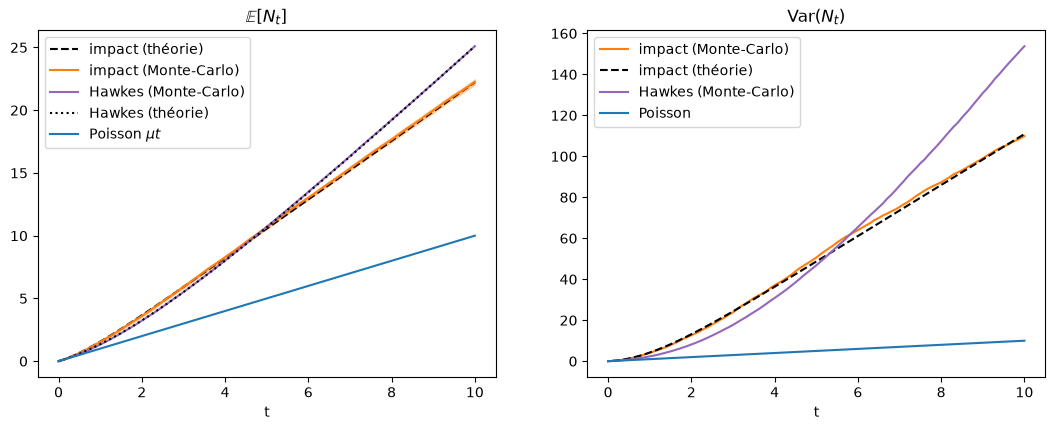

théorie dans la bande à 95 % : 95% des dates
E[N_T]   MC = 22.25 ± 0.21   théorie = 22.22
Var(N_T) MC = 109.9   théorie = 110.9   Poisson : 10.0
E[H_T]   MC = 25.10   théorie = 25.09   Var(H_T) MC = 153.8


In [5]:
K = 10000
grille = np.linspace(0, T, 101)
Ni = np.array([N_sur_grille(*simule_impact(T, mu, alpha, beta), grille) for _ in range(K)])
Nh = np.array([N_sur_grille(*simule_hawkes(T, mu, alpha, beta), grille) for _ in range(K)])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ic = 1.96 * Ni.std(axis=0) / np.sqrt(K)
ax[0].fill_between(grille, Ni.mean(axis=0) - ic, Ni.mean(axis=0) + ic, alpha=0.3, color="tab:orange")
ax[0].plot(grille, esperance_impact(grille, mu, alpha, beta), "k--", label="impact (théorie)")
ax[0].plot(grille, Ni.mean(axis=0), c="tab:orange", label="impact (Monte-Carlo)")
ax[0].plot(grille, Nh.mean(axis=0), c="tab:purple", label="Hawkes (Monte-Carlo)")
ax[0].plot(grille, esperance_hawkes(grille, mu, alpha, beta), "k:", label="Hawkes (théorie)")
ax[0].plot(grille, mu * grille, c="tab:blue", label=r"Poisson $\mu t$")
ax[0].set(xlabel="t", title=r"$\mathbb{E}[N_t]$"); ax[0].legend()
ax[1].plot(grille, Ni.var(axis=0), c="tab:orange", label="impact (Monte-Carlo)")
ax[1].plot(grille[1:], [variance_impact(x, mu, alpha, beta) for x in grille[1:]], "k--", label="impact (théorie)")
ax[1].plot(grille, Nh.var(axis=0), c="tab:purple", label="Hawkes (Monte-Carlo)")
ax[1].plot(grille, mu * grille, c="tab:blue", label="Poisson")
ax[1].set(xlabel="t", title=r"$\mathrm{Var}(N_t)$"); ax[1].legend()
plt.show()

theorie = esperance_impact(grille, mu, alpha, beta)
dedans = np.abs(Ni.mean(axis=0) - theorie) <= ic
print(f"théorie dans la bande à 95 % : {dedans[1:].mean():.0%} des dates")
print(f"E[N_T]   MC = {Ni[:, -1].mean():.2f} ± {ic[-1]:.2f}   théorie = {esperance_impact(T, mu, alpha, beta):.2f}")
print(f"Var(N_T) MC = {Ni[:, -1].var():.1f}   théorie = {variance_impact(T, mu, alpha, beta):.1f}   Poisson : {mu * T:.1f}")
print(f"E[H_T]   MC = {Nh[:, -1].mean():.2f}   théorie = {esperance_hawkes(T, mu, alpha, beta):.2f}   Var(H_T) MC = {Nh[:, -1].var():.1f}")

La formule de $\mathbb E[N_t]$ est dans la bande de confiance à 95 % pour environ 95 % des dates, ce qui est exactement ce qu'on attend d'une bande point par point. La formule de la variance colle aussi au Monte-Carlo. Au début $\mathbb E[N_t]\approx\mu t$ (pas encore d'impact), puis la pente monte vers $\mu(1+2\alpha/\beta)$. La grosse différence avec Poisson est la variance : environ 5 fois l'espérance, alors qu'elles sont égales pour Poisson. C'est la signature des grappes.

## 4. Rôle des paramètres

- $\mu$ : fréquence des sinistres spontanés (comme l'intensité du modèle de Poisson) ;
- $\alpha$ : force de l'impact juste après un sinistre (hauteur de la zone d'impact) ;
- $\beta$ : vitesse à laquelle l'impact s'éteint, $1/\beta$ est la durée typique de l'effet ;
- $\alpha/\beta=\int_0^\infty\Phi$ : nombre moyen de sinistres induits par un sinistre spontané (avant le poids `facteur`).

Dans le modèle à impact les sinistres induits n'induisent rien, donc $\mathbb E[N_t]$ reste fini même si $\alpha\ge\beta$. La condition $\alpha<\beta$ est celle de stabilité du Hawkes ; on la garde pour pouvoir comparer les deux modèles.

   mu  alpha  beta |  E[N_T]   Var(N_T)  Var/E  P(multi)
  0.5    0.8   1.2 |   11.11      46.3   4.17     0.41
  1.0    0.8   1.2 |   22.22     110.9   4.99     0.74


  2.0    0.8   1.2 |   44.44     294.6   6.63     0.93
  1.0    0.2   1.2 |   13.06      32.3   2.47     0.32
  1.0    0.6   1.2 |   19.17      82.7   4.32     0.65


  1.0    1.0   1.2 |   25.28     141.0   5.58     0.80
  1.0    0.8   0.9 |   25.80     160.2   6.21     0.82
  1.0    0.8   1.2 |   22.22     110.9   4.99     0.72


  1.0    0.8   3.0 |   15.16      39.7   2.62     0.35


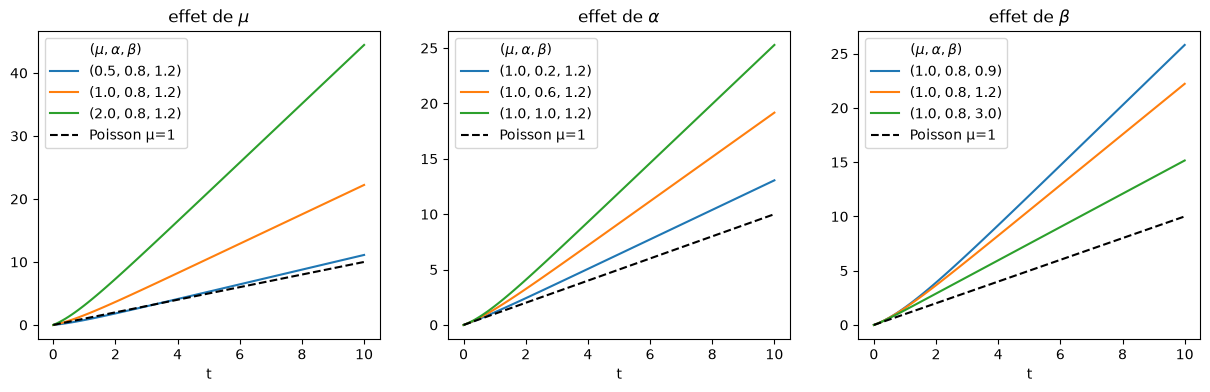

In [6]:
configs = {
    r"$\mu$": [(0.5, 0.8, 1.2), (1.0, 0.8, 1.2), (2.0, 0.8, 1.2)],
    r"$\alpha$": [(1.0, 0.2, 1.2), (1.0, 0.6, 1.2), (1.0, 1.0, 1.2)],
    r"$\beta$": [(1.0, 0.8, 0.9), (1.0, 0.8, 1.2), (1.0, 0.8, 3.0)],
}

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
print("   mu  alpha  beta |  E[N_T]   Var(N_T)  Var/E  P(multi)")
for j, (nom, liste) in enumerate(configs.items()):
    for (m_, a, b) in liste:
        E = esperance_impact(T, m_, a, b)
        V = variance_impact(T, m_, a, b)
        # P(multi) : proba qu'au moins un point soit induit par plusieurs parents à la fois
        sauts = [simule_impact(T, m_, a, b)[1] for _ in range(2000)]
        p_multi = np.mean([np.any(s > facteur) for s in sauts])
        print(f"{m_:5.1f} {a:6.1f} {b:5.1f} | {E:7.2f} {V:9.1f} {V / E:6.2f} {p_multi:8.2f}")
        ax[j].plot(grille, esperance_impact(grille, m_, a, b), label=f"({m_}, {a}, {b})")
    ax[j].plot(grille, mu * grille, "k--", label="Poisson µ=1")
    ax[j].set(title=f"effet de {nom}", xlabel="t"); ax[j].legend(title=r"$(\mu,\alpha,\beta)$")
plt.show()

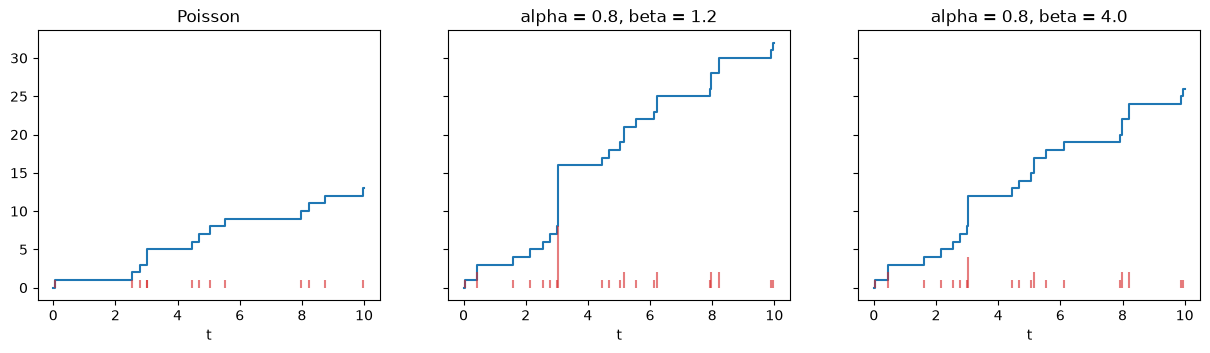

In [7]:
# trois trajectoires avec la même graine : Poisson, impact par défaut, impact qui s'éteint vite
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for j, (a, b) in enumerate([(0.0, 1.2), (0.8, 1.2), (0.8, 4.0)]):
    rng = np.random.default_rng(7)
    tk, sk = simule_poisson(T, mu) if a == 0 else simule_impact(T, mu, a, b)
    ax[j].step(np.r_[0, tk, T], np.r_[0, np.cumsum(sk), sk.sum()], where="post")
    ax[j].vlines(tk, 0, sk, colors="tab:red", alpha=0.6)
    ax[j].set(title=f"alpha = {a}, beta = {b}" if a else "Poisson", xlabel="t")
plt.show()
rng = np.random.default_rng(2025)

Lecture : $\mathbb E[N_t]$ est exactement linéaire en $\mu$ ; augmenter $\mu$ augmente aussi le rapport Var/E car il y a plus de zones qui se chevauchent. Augmenter $\alpha$ (ou diminuer $\beta$) ajoute des sinistres en grappes juste après les sinistres spontanés : l'espérance augmente, mais surtout la variance. Avec $\beta$ grand l'impact s'éteint vite et on retrouve presque un Poisson.

## 5. Montants des sinistres

Cinq lois de même moyenne $m=200$ € pour isoler l'effet de la forme de la loi :

- **discrète « dentaire »** : soin de carie 50 € (55 %), dévitalisation 150 € (25 %), couronne 500 € (15 %), bridge 1200 € (5 %) ;
- **exponentielle** de moyenne 200 ;
- **gamma** $\Gamma(2, 100)$, moins dispersée ;
- **log-normale** $\mathcal{LN}(\ln 200-\tfrac12, 1)$ ;
- **Pareto** $x_m=109.1$, $a=2.2$, queue lourde.

La log-normale et la Pareto n'ont pas de fonction génératrice des moments finie, donc pas de coefficient de Lundberg.

           loi  moyenne  écart-type exact   q99
      dentaire    200.1             276.6   1200
 exponentielle    200.4             200.0    922
         gamma    199.8             141.4    659
   log-normale    201.2             262.2   1263
        Pareto    199.9             301.5    885


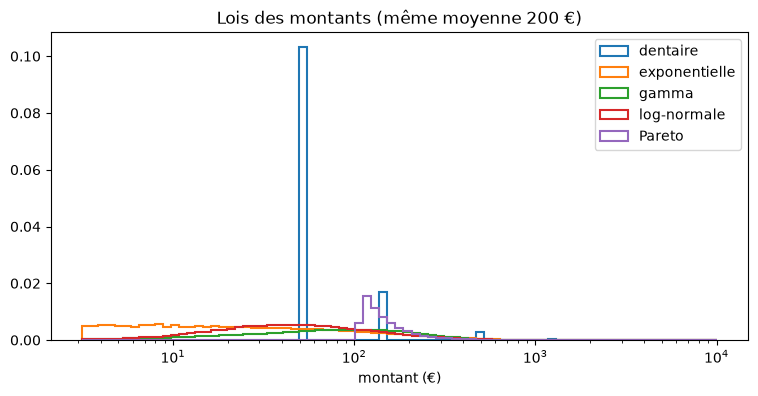

In [8]:
m = 200.0
montants = np.array([50, 150, 500, 1200])
probas = np.array([0.55, 0.25, 0.15, 0.05])
xm, a_par = m * 1.2 / 2.2, 2.2   # Pareto de moyenne 200

# une fonction de tirage par loi (numpy.pareto est une Lomax, d'où le 1 + ...)
lois = {
    "dentaire": lambda n: rng.choice(montants, n, p=probas),
    "exponentielle": lambda n: rng.exponential(m, n),
    "gamma": lambda n: rng.gamma(2, m / 2, n),
    "log-normale": lambda n: rng.lognormal(np.log(m) - 0.5, 1, n),
    "Pareto": lambda n: xm * (1 + rng.pareto(a_par, n)),
}
# variances exactes (plus fiables que l'empirique pour la Pareto)
var_Y = {
    "dentaire": (probas * montants ** 2).sum() - m ** 2,
    "exponentielle": m ** 2,
    "gamma": 2 * (m / 2) ** 2,
    "log-normale": m ** 2 * (np.e - 1),
    "Pareto": xm ** 2 * a_par / ((a_par - 1) ** 2 * (a_par - 2)),
}

fig, ax = plt.subplots(figsize=(9, 4))
print("           loi  moyenne  écart-type exact   q99")
for nom, loi in lois.items():
    y = loi(200000)
    print(f"{nom:>14} {y.mean():8.1f} {np.sqrt(var_Y[nom]):17.1f} {np.quantile(y, 0.99):6.0f}")
    ax.hist(y, bins=np.logspace(0.5, 4, 80), density=True, histtype="step", label=nom, lw=1.5)
ax.set(xscale="log", xlabel="montant (€)", title="Lois des montants (même moyenne 200 €)"); ax.legend()
plt.show()

## 6. Probabilité de ruine

### 6.1 Méthode et validation

La richesse ne baisse qu'aux sauts, il suffit donc de la regarder juste après chaque saut :
$$\psi(u,T)=\mathbb P\Big(\min_{j}\big(c\,t_j-L_j\big)<-u\Big)$$
où $L_j$ est le montant cumulé au $j$-ème saut. $u$ n'intervient qu'en translation : une seule simulation donne $\psi(u,T)$ pour tous les $u$.

Prime par le principe de l'espérance sur $[0,T]$ : $cT=(1+\eta)\,\mathbb E[N_T]\,m$ avec $\eta=20\%$.

In [9]:
eta = 0.2
us = np.linspace(0, 3000, 61)
u0 = 1000
i0 = np.searchsorted(us, u0)

def marge_min(temps, sauts, c, loi):
    # plus petite valeur de c*t - pertes, regardée juste après chaque saut
    if len(temps) == 0:
        return 0.0
    y = loi(sauts.sum())                         # un montant par sinistre
    pertes = np.cumsum(y)[np.cumsum(sauts) - 1]  # pertes cumulées après chaque saut
    return min(0.0, (c * temps - pertes).min())

def psi(trajs, c, loi):
    # ruine si u + marge_min < 0, pour tous les u d'un coup
    mins = np.array([marge_min(t, s, c, loi) for t, s in trajs])
    return np.array([(u + mins < 0).mean() for u in us])

**Validation sur le cas du cours** : Poisson + sinistres exponentiels sur un horizon long ($T=200$) ; on doit retrouver $\psi(u)=\frac{1}{1+\eta}e^{-\eta u/((1+\eta)m)}$.

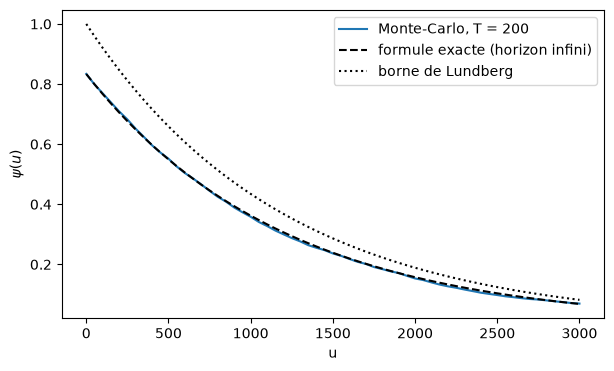

In [10]:
c_poisson = (1 + eta) * mu * m
val = [simule_poisson(200.0, mu) for _ in range(5000)]
plt.figure(figsize=(7, 4))
plt.plot(us, psi(val, c_poisson, lois["exponentielle"]), label="Monte-Carlo, T = 200")
plt.plot(us, np.exp(-eta * us / ((1 + eta) * m)) / (1 + eta), "k--", label="formule exacte (horizon infini)")
plt.plot(us, np.exp(-(1 / m - mu / c_poisson) * us), "k:", label="borne de Lundberg")
plt.xlabel("u"); plt.ylabel(r"$\psi(u)$"); plt.legend(); plt.show()

### 6.2 Comparaison des modèles

prime c (€/an) : {'Poisson': 240.0, 'impact': 533.3, 'Hawkes': 602.2}


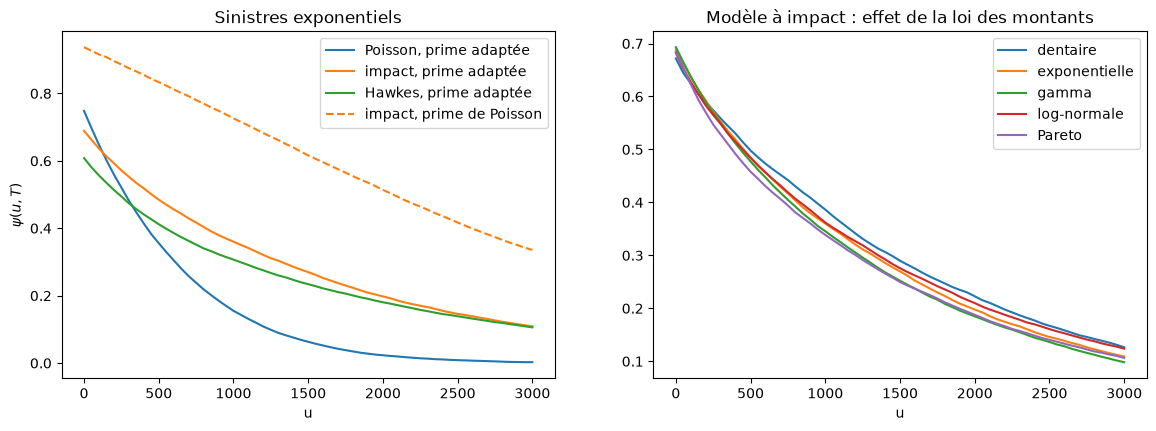

psi(u=1000, T=10)
           loi |  Poisson   impact   Hawkes | impact, prime Poisson
      dentaire |    0.227    0.386    0.335 |    0.711
 exponentielle |    0.155    0.360    0.307 |    0.726
         gamma |    0.112    0.346    0.282 |    0.729
   log-normale |    0.173    0.362    0.311 |    0.703
        Pareto |    0.115    0.339    0.280 |    0.714


In [11]:
K = 20000
traj = {
    "Poisson": [simule_poisson(T, mu) for _ in range(K)],
    "impact": [simule_impact(T, mu, alpha, beta) for _ in range(K)],
    "Hawkes": [simule_hawkes(T, mu, alpha, beta) for _ in range(K)],
}
EN = {"Poisson": mu * T, "impact": esperance_impact(T, mu, alpha, beta), "Hawkes": esperance_hawkes(T, mu, alpha, beta)}
c = {k: (1 + eta) * EN[k] * m / T for k in EN}
print("prime c (€/an) :", {k: round(float(v), 1) for k, v in c.items()})

# psi pour chaque modèle et chaque loi, avec la prime adaptée au modèle
res = {(k, nom): psi(traj[k], c[k], loi) for k in traj for nom, loi in lois.items()}
# l'assureur garde la prime de Poisson alors que les sinistres s'auto-excitent
res_pp = {nom: psi(traj["impact"], c["Poisson"], loi) for nom, loi in lois.items()}

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for k in traj:
    ax[0].plot(us, res[(k, "exponentielle")], label=f"{k}, prime adaptée")
ax[0].plot(us, res_pp["exponentielle"], "--", c="tab:orange", label="impact, prime de Poisson")
ax[0].set(xlabel="u", ylabel=r"$\psi(u,T)$", title="Sinistres exponentiels"); ax[0].legend()
for nom in lois:
    ax[1].plot(us, res[("impact", nom)], label=nom)
ax[1].set(xlabel="u", title="Modèle à impact : effet de la loi des montants"); ax[1].legend()
plt.show()

print(f"psi(u={u0}, T={T:.0f})")
print("           loi |  Poisson   impact   Hawkes | impact, prime Poisson")
for nom in lois:
    print(f"{nom:>14} | {res[('Poisson', nom)][i0]:8.3f} {res[('impact', nom)][i0]:8.3f} {res[('Hawkes', nom)][i0]:8.3f} | {res_pp[nom][i0]:8.3f}")

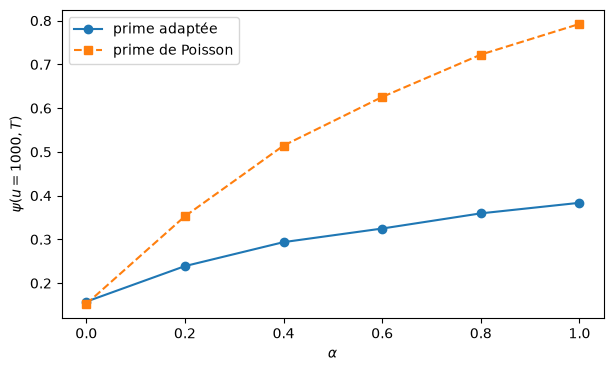

In [12]:
# effet de alpha sur la ruine (alpha = 0 : Poisson)
alphas = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
p_adaptee, p_poisson = [], []
for a in alphas:
    tr = [simule_impact(T, mu, a, beta) if a > 0 else simule_poisson(T, mu) for _ in range(10000)]
    ca = (1 + eta) * esperance_impact(T, mu, a, beta) * m / T
    p_adaptee.append(psi(tr, ca, lois["exponentielle"])[i0])
    p_poisson.append(psi(tr, c["Poisson"], lois["exponentielle"])[i0])
plt.figure(figsize=(7, 4))
plt.plot(alphas, p_adaptee, "o-", label="prime adaptée")
plt.plot(alphas, p_poisson, "s--", label="prime de Poisson")
plt.xlabel(r"$\alpha$"); plt.ylabel(fr"$\psi(u={u0},T)$"); plt.legend(); plt.show()

Lecture :
- la méthode est validée : sur le cas du cours on retrouve la formule exacte et on reste sous la borne de Lundberg ;
- un assureur qui garde la prime de Poisson alors que les sinistres s'auto-excitent passe d'environ 0,16 à 0,73 de probabilité de ruine (sinistres exponentiels), et ça empire quand $\alpha$ augmente ;
- même avec la prime adaptée, la ruine reste plus de deux fois plus probable que pour Poisson, sauf pour un capital très petit (environ 150 €) : là, la prime plus élevée protège au début, avant que les grappes ne démarrent ;
- le Hawkes ruine un peu moins que le modèle à impact sur 10 ans, alors qu'il a plus de sinistres. C'est une question de rythme : son intensité monte en régime en un temps de l'ordre de $1/(\beta-\alpha)=2{,}5$ ans, contre $1/\beta\approx0{,}8$ an pour le modèle à impact. Ses sinistres arrivent plus tard, et l'assureur a le temps d'accumuler des primes. Sur un horizon plus long ce ne serait plus vrai, car son coût moyen par an (600 €) rattrape presque sa prime (602 €) ;
- à moyenne égale, la loi dentaire donne la ruine la plus forte (des bridges rares mais chers) ; la Pareto et la gamma sont les plus faibles ici, la queue lourde de la Pareto ne pèse que pour de très grands $u$.

### 6.3 Comparaison à nombre moyen de sinistres égal

La comparaison précédente mélange deux effets : plus de sinistres en moyenne **et** des grappes. Pour isoler les grappes, on compare à un Poisson d'intensité $\lambda_{eq}=\mathbb E[N_T]/T$ : même nombre moyen de sinistres, donc même prime.

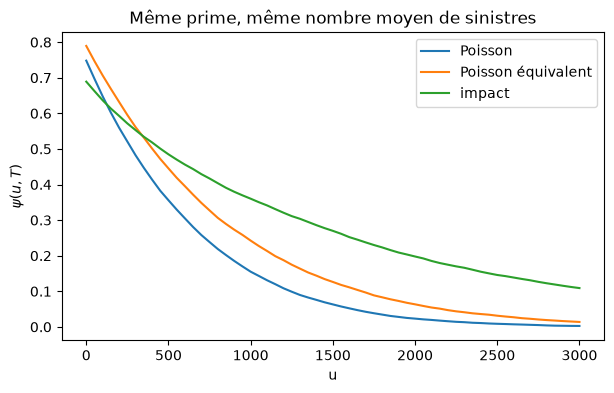

lambda_eq = 2.222, prime commune c = 533.3
psi(u=1000, T=10) à prime égale
           loi | Poisson équivalent   impact   écart
      dentaire |              0.328    0.386    +18%
 exponentielle |              0.242    0.360    +49%
         gamma |              0.182    0.346    +90%
   log-normale |              0.266    0.362    +36%
        Pareto |              0.184    0.339    +84%


In [13]:
lam_eq = EN["impact"] / T
traj_eq = [simule_poisson(T, lam_eq) for _ in range(K)]
res_eq = {nom: psi(traj_eq, c["impact"], loi) for nom, loi in lois.items()}

plt.figure(figsize=(7, 4))
plt.plot(us, res[("Poisson", "exponentielle")], label="Poisson")
plt.plot(us, res_eq["exponentielle"], label="Poisson équivalent")
plt.plot(us, res[("impact", "exponentielle")], label="impact")
plt.xlabel("u"); plt.ylabel(r"$\psi(u,T)$"); plt.title("Même prime, même nombre moyen de sinistres"); plt.legend(); plt.show()

print(f"lambda_eq = {lam_eq:.3f}, prime commune c = {c['impact']:.1f}")
print(f"psi(u={u0}, T={T:.0f}) à prime égale")
print("           loi | Poisson équivalent   impact   écart")
for nom in lois:
    p_eq, p_im = res_eq[nom][i0], res[("impact", nom)][i0]
    print(f"{nom:>14} | {p_eq:18.3f} {p_im:8.3f} {p_im / p_eq - 1:+7.0%}")

À nombre moyen de sinistres égal et à prime égale, le modèle à impact ruine nettement plus : environ +50 % pour des sinistres exponentiels. L'écart dépend de la loi des montants, de +18 % (dentaire) à +90 % (gamma). C'est l'effet propre des grappes : même moyenne, mais une variance de $N_T$ cinq fois plus grande. On voit aussi que la loi des montants change beaucoup la ruine dans le cas Poisson (de 0,18 à 0,33), et beaucoup moins dans le modèle à impact (de 0,34 à 0,39) : quand les sinistres arrivent en grappes, c'est le comptage qui domine le risque.

### 6.4 Une prime qui tient compte de la variance

Principe de la variance : $\pi_T=\mathbb E[S_T]+\delta\operatorname{Var}(S_T)$ avec
$$\operatorname{Var}(S_T)=\mathbb E[N_T]\operatorname{Var}(Y)+\operatorname{Var}(N_T)\,m^2$$
(valable ici car les $Y_i$ sont i.i.d. et indépendants de $N$, même avec des sauts de taille $>1$). On prend $\delta=\eta/(2m)$, ce qui redonne 20 % de chargement pour Poisson + exponentielle, et on garde ce $\delta$ partout. On compare les deux modèles avec ce même principe.

In [14]:
delta = eta / (2 * m)
VarN = {"Poisson": mu * T, "impact": variance_impact(T, mu, alpha, beta)}

def prime_variance(k, nom):
    ES = EN[k] * m
    VS = EN[k] * var_Y[nom] + VarN[k] * m ** 2
    return (ES + delta * VS) / T

print("           loi |  c Poisson  c impact | psi Poisson  psi impact (var.)  psi impact (esp.)")
for nom, loi in lois.items():
    cp, ci = prime_variance("Poisson", nom), prime_variance("impact", nom)
    pp = psi(traj["Poisson"], cp, loi)[i0]
    pi = psi(traj["impact"], ci, loi)[i0]
    print(f"{nom:>14} | {cp:10.1f} {ci:9.1f} | {pp:11.3f} {pi:18.3f} {res[('impact', nom)][i0]:18.3f}")

           loi |  c Poisson  c impact | psi Poisson  psi impact (var.)  psi impact (esp.)


      dentaire |      258.2     751.2 |       0.200              0.234              0.386


 exponentielle |      240.0     710.6 |       0.156              0.226              0.360


         gamma |      230.0     688.4 |       0.127              0.222              0.346


   log-normale |      254.4     742.6 |       0.157              0.222              0.362


        Pareto |      265.5     767.2 |       0.085              0.177              0.339


Avec le principe de la variance, la prime du modèle à impact monte à 690–770 € par an selon la loi, et la probabilité de ruine baisse d'environ 35 à 50 % (de 0,34–0,39 à 0,18–0,23). Elle reste plus élevée que celle d'un Poisson tarifé avec le même principe (de 1,2 fois pour la loi dentaire à 2 fois pour la Pareto) : le même $\delta$ ne suffit pas à compenser complètement les grappes. La prime s'adapte à la loi : la Pareto, la plus dispersée, reçoit le plus gros chargement. Recommandation : tarifer avec un chargement fondé sur la variance, et prévoir un $\delta$ plus élevé pour un portefeuille où les sinistres s'entraînent.

### 6.5 Que change le facteur 2 du sujet ?

Le facteur 2 double le nombre de sinistres induits. On refait les calculs principaux avec le poids 1 de l'article pour voir ce qui en dépend.

In [15]:
print("facteur |  E[N_T]  Var(N_T)  Var/E | prime Poisson / adaptée | impact vs Poisson équivalent")
for f in [2, 1]:
    E, V = esperance_impact(T, mu, alpha, beta, f), variance_impact(T, mu, alpha, beta, f)
    tr = [simule_impact(T, mu, alpha, beta, f) for _ in range(10000)]
    teq = [simule_poisson(T, E / T) for _ in range(10000)]
    cf = (1 + eta) * E * m / T
    p_pp = psi(tr, c["Poisson"], lois["exponentielle"])[i0]
    p_im = psi(tr, cf, lois["exponentielle"])[i0]
    p_eq = psi(teq, cf, lois["exponentielle"])[i0]
    print(f"{f:7d} | {E:7.2f} {V:9.1f} {V / E:6.2f} | {p_pp:.3f} / {p_im:.3f} (x{p_pp / res[('Poisson', 'exponentielle')][i0]:.1f} vs Poisson) | {p_im:.3f} vs {p_eq:.3f} ({p_im / p_eq - 1:+.0%})")

facteur |  E[N_T]  Var(N_T)  Var/E | prime Poisson / adaptée | impact vs Poisson équivalent


      2 |   22.22     110.9   4.99 | 0.726 / 0.363 (x4.7 vs Poisson) | 0.363 vs 0.245 (+48%)


      1 |   16.11      41.3   2.57 | 0.515 / 0.274 (x3.3 vs Poisson) | 0.274 vs 0.208 (+31%)


Avec le poids 1 de l'article, il y a moins de sinistres induits : la variance tombe à environ 2,6 fois l'espérance, garder la prime de Poisson multiplie la ruine par environ 3,3 (au lieu de 4,7), et l'écart avec le Poisson équivalent passe d'environ +50 % à +30 %. Les conclusions restent les mêmes, mais les chiffres dépendent beaucoup de ce choix : c'est le premier point à valider avec l'encadrant.

### 6.6 Horizon long

Les résultats du cours portent sur $\psi(u)=\mathbb P(\tau<\infty)$. On regarde $\psi(u,T)$ pour des horizons croissants. Sur un horizon long la prime doit couvrir le régime permanent : $c=(1+\eta)\,\mu(1+2\alpha/\beta)\,m$, et on compare à un Poisson de même taux limite. Pour Poisson, la formule exacte ne dépend pas de l'intensité, elle sert de repère.

T =  10 : psi(u=1000) Poisson = 0.249   impact = 0.329


T =  50 : psi(u=1000) Poisson = 0.351   impact = 0.519


T = 100 : psi(u=1000) Poisson = 0.359   impact = 0.533
formule exacte Poisson : 0.362   borne de Lundberg 'Poisson' : 0.435


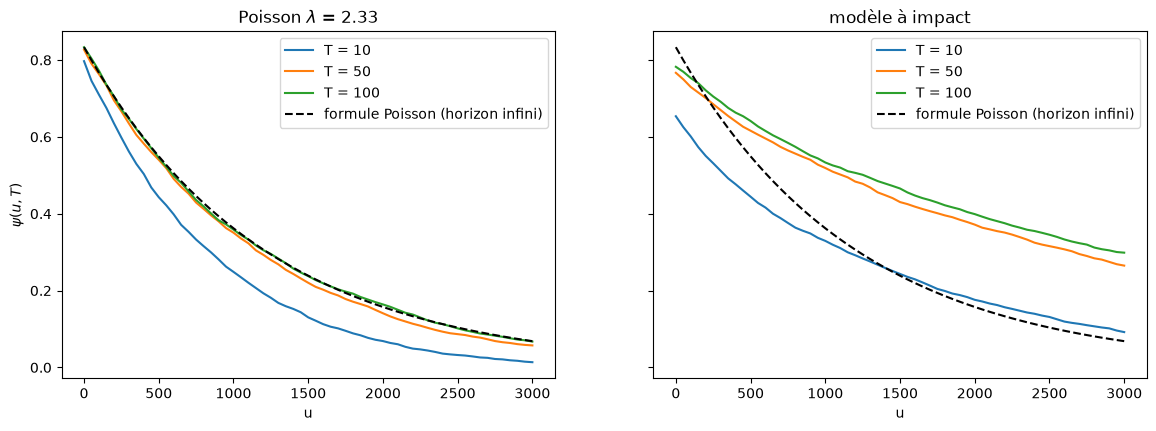

In [16]:
lam_inf = mu * (1 + facteur * alpha / beta)
c_inf = (1 + eta) * lam_inf * m
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for Tl in [10, 50, 100]:
    tp = [simule_poisson(Tl, lam_inf) for _ in range(3000)]
    ti = [simule_impact(Tl, mu, alpha, beta) for _ in range(3000)]
    pp, pi = psi(tp, c_inf, lois["exponentielle"]), psi(ti, c_inf, lois["exponentielle"])
    ax[0].plot(us, pp, label=f"T = {Tl}")
    ax[1].plot(us, pi, label=f"T = {Tl}")
    print(f"T = {Tl:3d} : psi(u={u0}) Poisson = {pp[i0]:.3f}   impact = {pi[i0]:.3f}")
exact = np.exp(-eta * us / ((1 + eta) * m)) / (1 + eta)
print(f"formule exacte Poisson : {exact[i0]:.3f}   borne de Lundberg 'Poisson' : {np.exp(-(1 / m - lam_inf / c_inf) * u0):.3f}")
for a in ax:
    a.plot(us, exact, "k--", label="formule Poisson (horizon infini)")
    a.set(xlabel="u"); a.legend()
ax[0].set(title=fr"Poisson $\lambda$ = {lam_inf:.2f}", ylabel=r"$\psi(u,T)$")
ax[1].set(title="modèle à impact")
plt.show()

Pour Poisson, $\psi(u,T)$ converge vers la formule exacte du cours (0,359 en $T=100$ contre 0,362). Pour le modèle à impact, la ruine continue d'augmenter avec l'horizon : elle vaut déjà 0,53 en $T=100$ et n'est pas encore stabilisée, avec pourtant la même prime et le même taux moyen de sinistres. Comme $\psi(u)\ge\psi(u,100)$, la borne de Lundberg calculée comme si le comptage était un Poisson ($e^{-Ru}\approx0{,}435$ pour $u=1000$) est dépassée : les outils du cours sous-estiment le risque de ce modèle.

### 6.7 Remarque sur les sauts de taille $k>1$

Un saut de taille $k$ est lu comme $k$ sinistres de montants indépendants survenus au même instant. C'est cohérent avec la définition de $N^{(2)}$, qui compte des couples (parent, enfant), et Wald reste vrai : $\mathbb E[S_T]=\mathbb E[N_T]\,m$. Une autre lecture serait un seul sinistre de montant multiplié par $k$ : même espérance, mais variance encore plus grande.

## 7. Propriétés du cours : que deviennent-elles ?

| Propriété | Poisson | Modèle à impact |
|---|---|---|
| accroissements indépendants | oui | non (un sinistre influence le futur) |
| accroissements stationnaires | oui | non, $\mathbb E[N_t]$ n'est pas linéaire au début |
| loi de $N_t$ | $\mathcal P(\mu t)$ | pas de forme simple ; $\operatorname{Var}>\mathbb E$ |
| sauts de taille 1 | oui | non (sinistres simultanés) |
| $\mathbb E[N_t]$ | $\mu t$ | $\mu t+2\frac{\mu\alpha}{\beta}\big(t-\frac{1-e^{-\beta t}}{\beta}\big)$ |
| Wald $\mathbb E[S_t]=\mathbb E[N_t]m$ | oui | oui ($Y$ indépendants de $N$) |
| $\operatorname{Var}(S_t)$ | $\mu t\,\mathbb E[Y^2]$ | $\mathbb E[N_t]\operatorname{Var}(Y)+\operatorname{Var}(N_t)\,m^2$ |
| profit net | $c>\mu m$ | $c>\mu(1+2\alpha/\beta)\,m$ |
| formule de ruine, Lundberg | oui | la preuve du cours (accroissements indépendants) ne s'applique plus, pas de formule fermée : Monte-Carlo |

## 8. Synthèse pour le N+1

- Le modèle à impact garde la structure de Cramér-Lundberg mais remplace l'arrivée « sans mémoire » des sinistres par des sinistres spontanés (fréquence $\mu$) qui en déclenchent d'autres pendant une durée de l'ordre de $1/\beta$, avec une force $\alpha$.
- L'espérance et la variance du nombre de sinistres sont explicites à toute date et vérifiées par simulation. L'espérance passe d'une pente $\mu$ à une pente $\mu(1+2\alpha/\beta)$ ; c'est une approximation à deux générations du processus de Hawkes.
- Ce qu'apporte le modèle par rapport à Poisson : des grappes de sinistres, une variance bien plus grande que la moyenne, et des sinistres simultanés.
- Une prime calibrée sur Poisson sous-estime fortement le risque. Même à moyenne et prime égales, les grappes seules augmentent nettement la ruine, et l'écart persiste sur un horizon long.
- Recommandation : estimer $\alpha$ et $\beta$ sur l'historique des sinistres et tarifer avec un chargement fondé sur la variance, plus élevé pour ce type de portefeuille.
- Limites : seulement deux générations, sauts de taille $>1$, paramètres fixés et non estimés, et le facteur 2 du sujet (contre $\frac1{2!}$ dans l'article) qui change beaucoup les chiffres et reste à valider.